# Simulasi Konsekuensi Internal Arc & Hidrolisis Gas SF6 pada Ruang GIS 150 kV

## 1. Setup, Konstanta Fisika-Kimia, & Model Probit

In [1]:
# %% [CELL 1] Setup, Pustaka, & Konstanta Fisika-Kimia (REVISI)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.stats import norm

# Konstanta Universal & Properti Fisik SF6
R_GAS = 8.3144626          # J/(mol.K)
N_AVOGADRO = 6.02214076e23 # molekul/mol
P_ATM = 101325.0           # Pa
M_SF6 = 0.14605            # kg/mol (IEEE Std C37.122.3-2024)
GAMMA_SF6 = 1.09           # Cp/Cv tipikal SF6 (gas poliatomik)
Z_SF6 = 0.935              # Faktor kompresibilitas real gas SF6 (~600 kPa, 30 C)

# Faktor Konversi Satuan Udara (ppm -> mg/m3)
# Sumber: NRC (2004) untuk HF; NRC (2010) untuk SO2
PPM_TO_MGM3 = {
    "HF": 0.82,
    "SO2": 2.60
}

# Tabel Ambang Darurat Akut AEGL (ppm)
# Sumber: NRC (2004) untuk HF; NRC (2010) untuk SO2
AEGL_HF = {
    "AEGL-1 (10-60 min)": 1.0,
    "AEGL-2 (10 min)": 95.0,
    "AEGL-2 (30 min)": 34.0,
    "AEGL-3 (10 min)": 170.0,
    "AEGL-3 (30 min)": 62.0,
    "IDLH (NIOSH)": 30.0
}

AEGL_SO2 = {
    "AEGL-1 (10-60 min)": 0.20,
    "AEGL-2 (10-60 min)": 0.75,
    "AEGL-3 (10-60 min)": 30.0,
    "IDLH (NIOSH)": 100.0
}

# Konstanta Probit Fatalitas: Y = A + B * ln(Integral C^n dt), t dalam menit
# Unit C dinyatakan eksplisit ('mg/m3' atau 'ppm') agar konversi otomatis & bebas error
PROBIT_MODELS = {
    # Model Utama HF: TNO Green Book / BEVI (2009) - Standar QRA Eropa (mg/m3, min)
    "HF_BEVI":      {"A": -8.620,  "B": 1.000, "n": 1.50, "unit": "mg/m3"},
    # Pembanding 1 HF: CCPS Terkoreksi (ioMosaic / Casal, 2008) - koreksi typo -35.87 (mg/m3, min)
    "HF_CCPS_CORR": {"A": -25.870, "B": 3.354, "n": 1.00, "unit": "mg/m3"},
    # Model Utama SO2: CCPS (1989) dalam James (2014) (ppm, min)
    "SO2_CCPS":     {"A": -15.670, "B": 2.100, "n": 1.00, "unit": "ppm"},
}

def derive_probit_constants(lc50_ppm, t_lc50_min, aegl3_ppm, t_aegl3_min, n):
    """
    Menurunkan konstanta Probit (A, B) dari data LC50 (50% fatal) dan AEGL-3 (~1% fatal)
    menggunakan Persamaan (6)-(7) James (2014).
    """
    dose_50 = (lc50_ppm ** n) * t_lc50_min
    dose_01 = (aegl3_ppm ** n) * t_aegl3_min
    z_50 = norm.ppf(0.50)  # 0.0
    z_01 = norm.ppf(0.01)  # -2.3263
    B = (z_50 - z_01) / (np.log(dose_50) - np.log(dose_01))
    A_unshifted = z_50 - B * np.log(dose_50)
    A_shifted = A_unshifted + 5.0  # Shift +5 agar sebanding dengan tabel Probit standar
    return {"A": A_shifted, "B": B, "n": n, "unit": "ppm"}

# Pembanding 2 HF (Batas Atas Konservatif): NRC AEGL (2004) n=2
# Berbasis 1-h LC50 mencit (342 ppm) dan 1-h AEGL-3 (44 ppm)
PROBIT_MODELS["HF_AEGL_N2"] = derive_probit_constants(
    lc50_ppm=342.0, t_lc50_min=60.0,
    aegl3_ppm=44.0, t_aegl3_min=60.0, n=2.0
)

print("Setup selesai (dengan koreksi Z_SF6 & Probit TNO BEVI 2009).")
for k, v in PROBIT_MODELS.items():
    print(f"  {k:14s}: A={v['A']:7.3f}, B={v['B']:.3f}, n={v['n']:.2f} (unit: {v['unit']})")

Setup selesai (dengan koreksi Z_SF6 & Probit TNO BEVI 2009).
  HF_BEVI       : A= -8.620, B=1.000, n=1.50 (unit: mg/m3)
  HF_CCPS_CORR  : A=-25.870, B=3.354, n=1.00 (unit: mg/m3)
  SO2_CCPS      : A=-15.670, B=2.100, n=1.00 (unit: ppm)
  HF_AEGL_N2    : A= -3.942, B=0.567, n=2.00 (unit: ppm)


## 2. Parameter Skenario Baseline (Input Panel)

In [2]:
# %% [CELL 2] Panel Input Skenario (Typical 150 kV 5-Bay GIS Substation)
@dataclass
class GISConfig:
    # --- Parameter Kompartemen GIS & Internal Arc ---
    p1_init_pa: float = 600e3         # Tekanan pengisian nominal (600 kPa abs)
    m_sf6_init_kg: float = 59.0       # Massa SF6 1 kompartemen CB 3-fasa (kg)
    t_gis_k: float = 303.15           # Suhu awal gas kompartemen (30 C)
    i_fault_a: float = 40e3           # Arus hubung singkat (40 kA rms)
    u_arc_v: float = 500.0            # Tegangan busur listrik tipikal (500 V)
    t_arc_s: float = 0.300            # Durasi busur (0.05 s normal; 0.30 s burn-through)
    d_orifice_m: float = 0.050        # Diameter lubang / bursting disc (50 mm)
    cd_orifice: float = 0.61          # Koefisien discharge sharp-edged orifice (CCPS)

    # --- Parameter Kimia & Kinetika Hidrolisis ---
    g_yield_mol_j: float = 600e-9     # Yield dekomposisi elektroda Al (Chu, 1986)
    alpha_sf4: float = 0.50           # Fraksi awal SF4 saat keluar (sisanya SOF2)
    k1_cm3_s: float = 2.0e-19         # Konstanta hidrolisis SF4 (Van Brunt & Sauers, 1986)
    k2_cm3_s: float = 1.2e-23         # Konstanta hidrolisis SOF2 fasa gas (Van Brunt, 1986)
    k_wall_hf_s: float = 0.0          # Wall loss HF pada logam (0 = konservatif)

    # --- Parameter Ruang GIS & Ventilasi ---
    v_room_m3: float = 2860.32        # Volume total ruang GIS (m3)
    f_strat: float = 0.25             # Fraksi volume efektif zona bawah pernapasan
    t_room_c: float = 30.0            # Suhu ruangan tropis (C)
    rh_frac: float = 0.75             # Kelembaban relatif ruangan (75%)
    ach_normal: float = 1.0           # Ventilasi normal (1/jam)
    ach_emergency: float = 6.0        # Exhaust darurat (1/jam)
    t_exhaust_on_s: float = 120.0     # Waktu aktivasi exhaust darurat (detik)

    # --- Durasi Simulasi ---
    t_sim_max_s: float = 3600.0       # 60 menit

def calc_h2o_molar_conc(t_c, rh_frac):
    """Menghitung konsentrasi molar uap air ruangan [H2O] (mol/m3) via Persamaan Antoine."""
    p_sat_mmhg = 10 ** (8.07131 - 1730.63 / (233.426 + t_c))
    p_sat_pa = p_sat_mmhg * 133.322368
    p_h2o_pa = rh_frac * p_sat_pa
    return p_h2o_pa / (R_GAS * (t_c + 273.15))

cfg_test = GISConfig()
c_h2o = calc_h2o_molar_conc(cfg_test.t_room_c, cfg_test.rh_frac)
print(f"Konsentrasi uap air ruangan ({cfg_test.t_room_c} C, RH {cfg_test.rh_frac*100:.0f}%): {c_h2o:.3f} mol/m3")
print(f"Volume efektif zona pernapasan (f_strat={cfg_test.f_strat}): {cfg_test.v_room_m3 * cfg_test.f_strat:.2f} m3")

Konsentrasi uap air ruangan (30.0 C, RH 75%): 1.259 mol/m3
Volume efektif zona pernapasan (f_strat=0.25): 715.08 m3


## 3. Model Deterministik: Orifice Blowdown & Kinetika Hidrolisis (ODE)

In [3]:
# %% [CELL 3] Mesin Deterministik Terkopel (Modul 1: Real-Gas Blowdown + Modul 2: ODE Hidrolisis) (REVISI)
def orifice_molar_flow(p1_pa, t1_k, area_m2, cd, p2_pa=P_ATM, z_factor=Z_SF6):
    """
    Menghitung laju alir molar gas (mol/s) melalui orifice berdasarkan CCPS CPQRA
    Pers. (2.1.16) subsonik dan (2.1.17)-(2.1.18) choked flow dengan koreksi faktor kompresibilitas Z.
    """
    if p1_pa <= p2_pa:
        return 0.0

    p_crit_ratio = (2.0 / (GAMMA_SF6 + 1.0)) ** (GAMMA_SF6 / (GAMMA_SF6 - 1.0))
    p_ratio = p2_pa / p1_pa

    if p_ratio <= p_crit_ratio:
        # Choked (Sonic) Flow - CCPS Eq. (2.1.17) + faktor Z
        term = (GAMMA_SF6 * M_SF6 / (z_factor * R_GAS * t1_k)) * \
               ((2.0 / (GAMMA_SF6 + 1.0)) ** ((GAMMA_SF6 + 1.0) / (GAMMA_SF6 - 1.0)))
        m_dot = cd * area_m2 * p1_pa * np.sqrt(term)
    else:
        # Non-Choked (Subsonic) Flow - CCPS Eq. (2.1.16) + faktor Z
        bracket = max(0.0, (p_ratio ** (2.0 / GAMMA_SF6)) - (p_ratio ** ((GAMMA_SF6 + 1.0) / GAMMA_SF6)))
        term = (2.0 * M_SF6 / (z_factor * R_GAS * t1_k)) * (GAMMA_SF6 / (GAMMA_SF6 - 1.0)) * bracket
        m_dot = cd * area_m2 * p1_pa * np.sqrt(term)

    return m_dot / M_SF6  # mol/s

def run_deterministic_simulation(cfg: GISConfig):
    """
    Menyelesaikan sistem 6 ODE terkopel (Blowdown kompartemen + Neraca massa ruangan + Hidrolisis):
    State vector y = [N_tank, C_SF6, C_SF4, C_SOF2, C_SO2, C_HF]
    """
    # 1. Source Term Internal Arc & Volume Kompartemen (Real Gas Z_SF6)
    e_arc_j = cfg.u_arc_v * cfg.i_fault_a * cfg.t_arc_s
    n_dec_total = cfg.g_yield_mol_j * e_arc_j
    n_sf6_init = cfg.m_sf6_init_kg / M_SF6
    v_gis_m3 = (Z_SF6 * n_sf6_init * R_GAS * cfg.t_gis_k) / cfg.p1_init_pa

    # Fraksi molar kontaminan di dalam kompartemen sebelum blowdown
    y_sf4_tank = (cfg.alpha_sf4 * n_dec_total) / n_sf6_init
    y_sof2_tank = ((1.0 - cfg.alpha_sf4) * n_dec_total) / n_sf6_init
    y_sf6_tank = max(0.0, 1.0 - y_sf4_tank - y_sof2_tank)

    # 2. Parameter Ruangan & Kinetika SI
    v_eff = cfg.v_room_m3 * cfg.f_strat
    area_orifice = np.pi * (cfg.d_orifice_m / 2.0) ** 2
    c_h2o = calc_h2o_molar_conc(cfg.t_room_c, cfg.rh_frac)

    # Konversi konstanta laju dari cm3/(molekul.s) -> m3/(mol.s)
    k1_si = cfg.k1_cm3_s * N_AVOGADRO * 1e-6
    k2_si = cfg.k2_cm3_s * N_AVOGADRO * 1e-6

    def ode_system(t, y):
        n_tank, c_sf6, c_sf4, c_sof2, c_so2, c_hf = y

        # Tekanan internal kompartemen saat t (konsisten dengan Z_SF6)
        p1_curr = (Z_SF6 * n_tank * R_GAS * cfg.t_gis_k) / v_gis_m3
        n_dot_out = orifice_molar_flow(p1_curr, cfg.t_gis_k, area_orifice, cfg.cd_orifice)

        # Laju ventilasi dinamis (ACH normal -> emergency exhaust)
        ach_curr = cfg.ach_emergency if t >= cfg.t_exhaust_on_s else cfg.ach_normal
        lam_vent = ach_curr / 3600.0  # 1/s

        # Laju reaksi hidrolisis (mol/(m3.s))
        r1 = k1_si * max(0.0, c_sf4) * c_h2o
        r2 = k2_si * max(0.0, c_sof2) * c_h2o

        # Sistem 6 ODE
        dN_tank = -n_dot_out
        dC_sf6  = (y_sf6_tank * n_dot_out) / v_eff - lam_vent * c_sf6
        dC_sf4  = (y_sf4_tank * n_dot_out) / v_eff - r1 - lam_vent * c_sf4
        dC_sof2 = (y_sof2_tank * n_dot_out) / v_eff + r1 - r2 - lam_vent * c_sof2
        dC_so2  = r2 - lam_vent * c_so2
        dC_hf   = 2.0 * r1 + 2.0 * r2 - (lam_vent + cfg.k_wall_hf_s) * c_hf

        return [dN_tank, dC_sf6, dC_sf4, dC_sof2, dC_so2, dC_hf]

    # Grid waktu rapat di awal (0-30 s) agar blowdown & hidrolisis cepat SF4 terekam halus
    t_eval = np.unique(np.concatenate([
        np.linspace(0, 30, 300),
        np.linspace(30, 300, 270),
        np.linspace(300, cfg.t_sim_max_s, 330)
    ]))

    y0 = [n_sf6_init, 0.0, 0.0, 0.0, 0.0, 0.0]

    # Wajib gunakan method='Radau' karena sistem ODE bersifat stiff
    sol = solve_ivp(
        ode_system, [0, cfg.t_sim_max_s], y0,
        method='Radau', t_eval=t_eval, rtol=1e-6, atol=1e-10
    )

    if not sol.success:
        raise RuntimeError(f"ODE Solver gagal: {sol.message}")

    # Konversi hasil ke DataFrame & satuan praktis (kPa, ppmv, % O2)
    t_s = sol.t
    n_tank, c_sf6, c_sf4, c_sof2, c_so2, c_hf = sol.y
    p1_kpa = ((Z_SF6 * n_tank * R_GAS * cfg.t_gis_k) / v_gis_m3) / 1000.0
    molar_to_ppm = (R_GAS * (cfg.t_room_c + 273.15) / P_ATM) * 1e6

    df = pd.DataFrame({
        "time_s": t_s,
        "time_min": t_s / 60.0,
        "P_gis_kPa": p1_kpa,
        "SF6_ppm": np.maximum(0.0, c_sf6) * molar_to_ppm,
        "SF4_ppm": np.maximum(0.0, c_sf4) * molar_to_ppm,
        "SOF2_ppm": np.maximum(0.0, c_sof2) * molar_to_ppm,
        "SO2_ppm": np.maximum(0.0, c_so2) * molar_to_ppm,
        "HF_ppm": np.maximum(0.0, c_hf) * molar_to_ppm,
    })
    df["O2_pct"] = 20.95 * (1.0 - df["SF6_ppm"] / 1e6)

    meta = {
        "E_arc_MJ": e_arc_j / 1e6,
        "N_dec_mol": n_dec_total,
        "Dec_pct_in_tank": (n_dec_total / n_sf6_init) * 100.0,
        "V_gis_m3": v_gis_m3,
        "V_eff_m3": v_eff,
        "Frac_gas_released_pct": ((n_sf6_init - n_tank[-1]) / n_sf6_init) * 100.0
    }
    return df, meta

## 4. Evaluasi Toksikologi: Toxic Load & Multi-Model Probit

In [4]:
# %% [CELL 4] Evaluasi Konsekuensi: Toxic Load & Multi-Model Probit (Modul 3) (REVISI)
def calc_probit_profile(conc_ppm, time_min, probit_params, species):
    """
    Menghitung akumulasi Toxic Load (aturan trapesium) dan probabilitas fatalitas (%)
    mengikuti James (2014) Persamaan (8)-(9) dengan konversi satuan otomatis.
    """
    A, B, n = probit_params["A"], probit_params["B"], probit_params["n"]
    c_val = conc_ppm * PPM_TO_MGM3[species] if probit_params["unit"] == "mg/m3" else conc_ppm

    tl = cumulative_trapezoid(c_val ** n, time_min, initial=0.0)
    probit_y = np.where(tl > 1e-12, A + B * np.log(np.maximum(tl, 1e-12)), -np.inf)
    pf = norm.cdf(probit_y - 5.0)
    return tl, probit_y, pf

def evaluate_consequences(df):
    """Menambahkan kolom Probabilitas Fatalitas (BEVI 2009, CCPS Terkoreksi, & NRC AEGL n=2)."""
    t_min = df["time_min"].values
    hf_ppm = df["HF_ppm"].values
    so2_ppm = df["SO2_ppm"].values

    # SO2 (CCPS)
    _, _, pf_so2 = calc_probit_profile(so2_ppm, t_min, PROBIT_MODELS["SO2_CCPS"], "SO2")

    # 1. Model Utama: TNO BEVI (2009) untuk HF + CCPS untuk SO2
    _, _, pf_hf_bevi = calc_probit_profile(hf_ppm, t_min, PROBIT_MODELS["HF_BEVI"], "HF")
    pf_total_bevi = 1.0 - (1.0 - pf_hf_bevi) * (1.0 - pf_so2)

    # 2. Pembanding 1: CCPS Terkoreksi (-25.87, n=1) untuk HF + CCPS untuk SO2
    _, _, pf_hf_ccps = calc_probit_profile(hf_ppm, t_min, PROBIT_MODELS["HF_CCPS_CORR"], "HF")
    pf_total_ccps = 1.0 - (1.0 - pf_hf_ccps) * (1.0 - pf_so2)

    # 3. Pembanding 2 (Batas Atas): NRC AEGL (n=2) untuk HF + CCPS untuk SO2
    _, _, pf_hf_n2 = calc_probit_profile(hf_ppm, t_min, PROBIT_MODELS["HF_AEGL_N2"], "HF")
    pf_total_n2 = 1.0 - (1.0 - pf_hf_n2) * (1.0 - pf_so2)

    df = df.copy()
    df["Pf_SO2_CCPS_pct"] = pf_so2 * 100.0
    df["Pf_HF_BEVI_pct"] = pf_hf_bevi * 100.0
    df["Pf_Total_BEVI_pct"] = pf_total_bevi * 100.0
    df["Pf_HF_CCPS_pct"] = pf_hf_ccps * 100.0
    df["Pf_Total_CCPS_pct"] = pf_total_ccps * 100.0
    df["Pf_HF_AEGL_n2_pct"] = pf_hf_n2 * 100.0
    df["Pf_Total_AEGL_n2_pct"] = pf_total_n2 * 100.0
    return df

## 5. Analisis Deterministik: Perbandingan 4 Skenario Kritis

### 5.1 Ringkasan Kuantitatif Skenario

In [5]:
# %% [CELL 5] Eksekusi 4 Skenario Perbandingan Kritis & Tabel Ringkasan (REVISI)
scenarios = {
    "S1: Proteksi Normal (50 ms)": GISConfig(t_arc_s=0.050),
    "S2: Burn-Through (300 ms, Gas-Phase k2)": GISConfig(t_arc_s=0.300, k2_cm3_s=1.2e-23),
    "S3: Burn-Through (300 ms, Surface k2)": GISConfig(t_arc_s=0.300, k2_cm3_s=4.0e-20),
    "S4: Burn-Through (300 ms, Exhaust Gagal)": GISConfig(
        t_arc_s=0.300, k2_cm3_s=4.0e-20, ach_normal=0.2, ach_emergency=0.2
    ),
}

results = {}
summary_rows = []

for name, cfg in scenarios.items():
    df_sim, meta = run_deterministic_simulation(cfg)
    df_eval = evaluate_consequences(df_sim)
    results[name] = (df_eval, meta)

    # Ambil nilai pada t = 10 menit dan 30 menit
    idx_10 = np.argmin(np.abs(df_eval["time_min"] - 10.0))
    idx_30 = np.argmin(np.abs(df_eval["time_min"] - 30.0))

    summary_rows.append({
        "Skenario": name,
        "E_arc (MJ)": round(meta["E_arc_MJ"], 2),
        "Dec. Gas (%)": round(meta["Dec_pct_in_tank"], 2),
        "Peak HF (ppm)": round(df_eval["HF_ppm"].max(), 1),
        "Peak SO2 (ppm)": round(df_eval["SO2_ppm"].max(), 1),
        "Min O2 (%)": round(df_eval["O2_pct"].min(), 2),
        "Pf 10m BEVI (%)": round(df_eval["Pf_Total_BEVI_pct"].iloc[idx_10], 2),
        "Pf 30m BEVI (%)": round(df_eval["Pf_Total_BEVI_pct"].iloc[idx_30], 2),
        "Pf 30m CCPS (%)": round(df_eval["Pf_Total_CCPS_pct"].iloc[idx_30], 2),
        "Pf 30m AEGL-n2 (%)": round(df_eval["Pf_Total_AEGL_n2_pct"].iloc[idx_30], 2),
    })

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

,Skenario,E_arc (MJ),Dec. Gas (%),Peak HF (ppm),Peak SO2 (ppm),Min O2 (%),Pf 10m BEVI (%),Pf 30m BEVI (%),Pf 30m CCPS (%),Pf 30m AEGL-n2 (%)
0,S1: Proteksi Normal (50 ms),1.0,0.15,17.1,0.0,20.71,0.00,0.00,0.00,0.00
1,"S2: Burn-Through (300 ms, Gas-Phase k2)",6.0,0.89,102.6,0.2,20.71,0.00,0.00,0.00,0.43
2,"S3: Burn-Through (300 ms, Surface k2)",6.0,0.89,294.3,96.7,20.71,0.02,0.05,0.00,7.61
3,"S4: Burn-Through (300 ms, Exhaust Gagal)",6.0,0.89,308.3,102.7,20.71,0.10,2.28,13.73,28.48


### 5.2 Visualisasi Dinamika Gas & Sensitivitas Probit

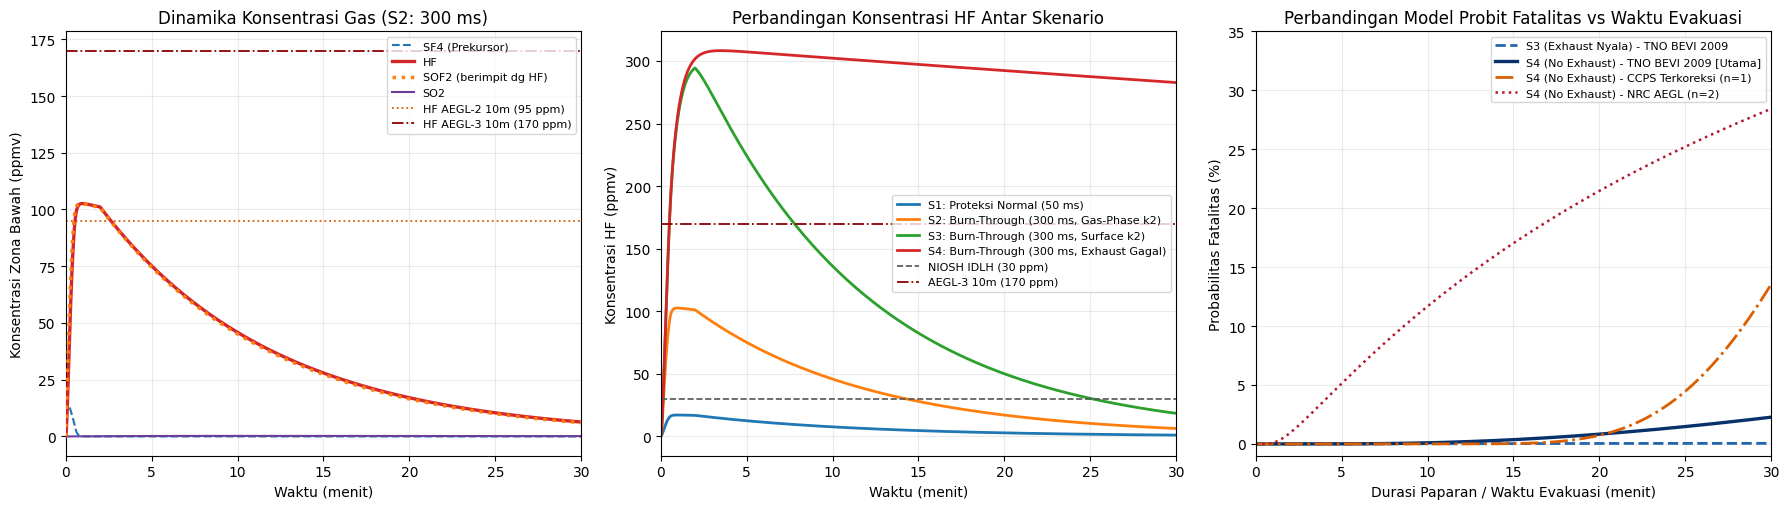

In [6]:
# %% [CELL 6] Visualisasi Hasil Deterministik (REVISI)
plt.rcParams.update({"axes.facecolor": "white", "figure.facecolor": "white"})
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Plot 1: Dinamika Gas pada Skenario Burn-Through (S2: Gas-Phase k2)
df_s2 = results["S2: Burn-Through (300 ms, Gas-Phase k2)"][0]
axes[0].plot(df_s2["time_min"], df_s2["SF4_ppm"], label="SF4 (Prekursor)", linestyle="--", color="#1f77b4")
axes[0].plot(df_s2["time_min"], df_s2["HF_ppm"], label="HF", linewidth=2.4, color="#d62728", zorder=3)
axes[0].plot(df_s2["time_min"], df_s2["SOF2_ppm"], label="SOF2 (berimpit dg HF)", linestyle=":", linewidth=2.5, color="#ff7f0e", zorder=5)
axes[0].plot(df_s2["time_min"], df_s2["SO2_ppm"], label="SO2", color="#6a3d9a")
axes[0].axhline(AEGL_HF["AEGL-2 (10 min)"], color="#d95f02", linestyle=":", linewidth=1.3, label="HF AEGL-2 10m (95 ppm)")
axes[0].axhline(AEGL_HF["AEGL-3 (10 min)"], color="#8c0000", linestyle="-.", linewidth=1.3, label="HF AEGL-3 10m (170 ppm)")
axes[0].set_xlim(0, 30)
axes[0].set_title("Dinamika Konsentrasi Gas (S2: 300 ms)")
axes[0].set_xlabel("Waktu (menit)")
axes[0].set_ylabel("Konsentrasi Zona Bawah (ppmv)")
axes[0].legend(fontsize=8, frameon=True)
axes[0].grid(True, alpha=0.25)

# Plot 2: Perbandingan Kurva HF Antar 4 Skenario
for name, (df_ev, _) in results.items():
    axes[1].plot(df_ev["time_min"], df_ev["HF_ppm"], linewidth=2.0, label=name)
axes[1].axhline(AEGL_HF["IDLH (NIOSH)"], color="#555555", linestyle="--", linewidth=1.2, label="NIOSH IDLH (30 ppm)")
axes[1].axhline(AEGL_HF["AEGL-3 (10 min)"], color="#8c0000", linestyle="-.", linewidth=1.3, label="AEGL-3 10m (170 ppm)")
axes[1].set_xlim(0, 30)
axes[1].set_title("Perbandingan Konsentrasi HF Antar Skenario")
axes[1].set_xlabel("Waktu (menit)")
axes[1].set_ylabel("Konsentrasi HF (ppmv)")
axes[1].legend(fontsize=8, frameon=True)
axes[1].grid(True, alpha=0.25)

# Plot 3: Sensitivitas Model Probit (BEVI 2009 vs CCPS Terkoreksi vs AEGL n=2)
df_s3 = results["S3: Burn-Through (300 ms, Surface k2)"][0]
df_s4 = results["S4: Burn-Through (300 ms, Exhaust Gagal)"][0]
axes[2].plot(df_s3["time_min"], df_s3["Pf_Total_BEVI_pct"], color="#2166ac", linewidth=2.0, linestyle="--", label="S3 (Exhaust Nyala) - TNO BEVI 2009")
axes[2].plot(df_s4["time_min"], df_s4["Pf_Total_BEVI_pct"], color="#08306b", linewidth=2.4, label="S4 (No Exhaust) - TNO BEVI 2009 [Utama]")
axes[2].plot(df_s4["time_min"], df_s4["Pf_Total_CCPS_pct"], color="#d95f02", linewidth=2.0, linestyle="-.", label="S4 (No Exhaust) - CCPS Terkoreksi (n=1)")
axes[2].plot(df_s4["time_min"], df_s4["Pf_Total_AEGL_n2_pct"], color="#b2182b", linewidth=1.8, linestyle=":", label="S4 (No Exhaust) - NRC AEGL (n=2)")
axes[2].set_xlim(0, 30)
axes[2].set_ylim(-1, 35)
axes[2].set_title("Perbandingan Model Probit Fatalitas vs Waktu Evakuasi")
axes[2].set_xlabel("Durasi Paparan / Waktu Evakuasi (menit)")
axes[2].set_ylabel("Probabilitas Fatalitas (%)")
axes[2].legend(fontsize=8, frameon=True)
axes[2].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## 6. Analisis Probabilistik (Simulasi Monte Carlo)

### 6.1 Engine Sampling & Eksekusi Monte Carlo

In [7]:
# %% [CELL 7] Engine Simulasi Monte Carlo (N = 1.000 Iterasi, Fixed Seed) (REVISI)
import time
from scipy.stats import spearmanr

def run_monte_carlo(n_iter=1000, seed=42):
    rng = np.random.default_rng(seed)
    t_start = time.time()

    # Grid waktu standar untuk menyimpan pita persentil (0-30 menit, 181 titik)
    t_grid_min = np.linspace(0, 30, 181)
    hf_curves = np.zeros((n_iter, len(t_grid_min)))
    records = []

    print(f"Memulai simulasi Monte Carlo ({n_iter} iterasi)...")
    for i in range(n_iter):
        # Sampling 8 variabel stokastik
        i_fault = rng.triangular(15e3, 30e3, 40e3)
        t_arc = rng.triangular(0.050, 0.300, 0.500)
        g_yield = rng.triangular(100e-9, 600e-9, 650e-9)
        alpha_sf4 = rng.uniform(0.20, 0.80)
        k2_val = 10 ** rng.uniform(np.log10(1.2e-23), np.log10(4.0e-20))
        f_strat = rng.uniform(0.20, 0.50)

        # Model keandalan exhaust (15% gagal beroperasi -> 0.2 ACH; 85% normal -> 4-8 ACH)
        exhaust_fail = rng.random() < 0.15
        ach_emerg = 0.2 if exhaust_fail else rng.uniform(4.0, 8.0)
        ach_norm = 0.2 if exhaust_fail else 1.0
        t_evac_min = rng.triangular(2.0, 10.0, 30.0)

        cfg = GISConfig(
            i_fault_a=i_fault,
            t_arc_s=t_arc,
            g_yield_mol_j=g_yield,
            alpha_sf4=alpha_sf4,
            k2_cm3_s=k2_val,
            f_strat=f_strat,
            ach_normal=ach_norm,
            ach_emergency=ach_emerg,
            t_sim_max_s=1800.0  # 30 menit
        )

        df_sim, meta = run_deterministic_simulation(cfg)
        df_eval = evaluate_consequences(df_sim)

        # Interpolasi kurva HF ke grid waktu seragam untuk pita persentil
        hf_curves[i, :] = np.interp(t_grid_min, df_eval["time_min"], df_eval["HF_ppm"])

        # Ekstraksi probabilitas fatalitas (Utama: TNO BEVI 2009; Batas Atas: NRC AEGL n=2)
        pf_evac_bevi = float(np.interp(t_evac_min, df_eval["time_min"], df_eval["Pf_Total_BEVI_pct"]))
        pf_10m_bevi = float(np.interp(10.0, df_eval["time_min"], df_eval["Pf_Total_BEVI_pct"]))
        pf_evac_n2 = float(np.interp(t_evac_min, df_eval["time_min"], df_eval["Pf_Total_AEGL_n2_pct"]))

        records.append({
            "I_fault (kA)": i_fault / 1e3,
            "t_arc (ms)": t_arc * 1e3,
            "G_yield (nmol/J)": g_yield * 1e9,
            "alpha_SF4": alpha_sf4,
            "log10_k2": np.log10(k2_val),
            "f_strat": f_strat,
            "ACH_emerg": ach_emerg,
            "t_evac (min)": t_evac_min,
            "E_arc (MJ)": meta["E_arc_MJ"],
            "Peak_HF (ppm)": df_eval["HF_ppm"].max(),
            "Peak_SO2 (ppm)": df_eval["SO2_ppm"].max(),
            "Min_O2 (%)": df_eval["O2_pct"].min(),
            "Pf_10m_BEVI (%)": pf_10m_bevi,
            "Pf_evac_BEVI (%)": pf_evac_bevi,
            "Pf_evac_AEGL_n2 (%)": pf_evac_n2
        })

        if (i + 1) % 200 == 0:
            print(f"  Selesai {i + 1}/{n_iter} iterasi ({time.time() - t_start:.1f} dtk)")

    print(f"Monte Carlo selesai dalam {time.time() - t_start:.1f} detik.")
    return pd.DataFrame(records), t_grid_min, hf_curves

df_mc, t_grid_min, hf_curves = run_monte_carlo(n_iter=1000, seed=42)

Memulai simulasi Monte Carlo (1000 iterasi)...
  Selesai 200/1000 iterasi (18.6 dtk)
  Selesai 400/1000 iterasi (47.8 dtk)
  Selesai 600/1000 iterasi (65.6 dtk)
  Selesai 800/1000 iterasi (83.9 dtk)
  Selesai 1000/1000 iterasi (102.7 dtk)
Monte Carlo selesai dalam 102.7 detik.


### 6.2 Statistik Persentil & Probabilitas Pelampauan Ambang Bahaya

In [8]:
# %% [CELL 8] Ringkasan Statistik Probabilistik & Pelampauan Ambang Darurat (REVISI)
metrics = [
    "E_arc (MJ)", "Peak_HF (ppm)", "Peak_SO2 (ppm)",
    "Min_O2 (%)", "Pf_evac_BEVI (%)", "Pf_evac_AEGL_n2 (%)"
]
stats_table = pd.DataFrame({
    "Mean": df_mc[metrics].mean(),
    "P5 (Optimis)": df_mc[metrics].quantile(0.05),
    "P50 (Median)": df_mc[metrics].quantile(0.50),
    "P95 (Konservatif)": df_mc[metrics].quantile(0.95),
    "Max": df_mc[metrics].max()
}).round(3)

print("=== RINGKASAN STATISTIK MONTE CARLO (N = 1.000) ===")
display(stats_table)

# Probabilitas melampaui ambang darurat akut HF & O2
p_idlh = (df_mc["Peak_HF (ppm)"] >= AEGL_HF["IDLH (NIOSH)"]).mean() * 100
p_aegl2 = (df_mc["Peak_HF (ppm)"] >= AEGL_HF["AEGL-2 (10 min)"]).mean() * 100
p_aegl3 = (df_mc["Peak_HF (ppm)"] >= AEGL_HF["AEGL-3 (10 min)"]).mean() * 100
p_o2_low = (df_mc["Min_O2 (%)"] <= 16.0).mean() * 100
p_fatal_bevi_gt1 = (df_mc["Pf_evac_BEVI (%)"] >= 1.0).mean() * 100
p_fatal_n2_gt1 = (df_mc["Pf_evac_AEGL_n2 (%)"] >= 1.0).mean() * 100

print("\n=== PROBABILITAS PELAMPAUAN AMBANG BAHAYA ===")
print(f"• Peak HF >= NIOSH IDLH (30 ppm):           {p_idlh:.1f}%")
print(f"• Peak HF >= AEGL-2 10-min (95 ppm):        {p_aegl2:.1f}%")
print(f"• Peak HF >= AEGL-3 10-min (170 ppm):       {p_aegl3:.1f}%")
print(f"• Fatalitas (TNO BEVI 2009) >= 1% saat evac:{p_fatal_bevi_gt1:.1f}%")
print(f"• Fatalitas (AEGL n=2) >= 1% saat evac:     {p_fatal_n2_gt1:.1f}%")
print(f"• Defisiensi O2 <= 16% (Asfiksia):          {p_o2_low:.1f}%")

=== RINGKASAN STATISTIK MONTE CARLO (N = 1.000) ===


,Mean,P5 (Optimis),P50 (Median),P95 (Konservatif),Max
E_arc (MJ),4.035,1.676,3.973,6.608,8.208
Peak_HF (ppm),59.889,12.961,47.691,149.716,504.966
Peak_SO2 (ppm),12.054,0.136,5.092,42.242,140.878
Min_O2 (%),20.764,20.667,20.777,20.826,20.829
Pf_evac_BEVI (%),0.003,0.000,0.000,0.001,1.168
Pf_evac_AEGL_n2 (%),0.366,0.000,0.029,1.538,26.661



=== PROBABILITAS PELAMPAUAN AMBANG BAHAYA ===
• Peak HF >= NIOSH IDLH (30 ppm):           72.5%
• Peak HF >= AEGL-2 10-min (95 ppm):        16.2%
• Peak HF >= AEGL-3 10-min (170 ppm):       2.9%
• Fatalitas (TNO BEVI 2009) >= 1% saat evac:0.1%
• Fatalitas (AEGL n=2) >= 1% saat evac:     7.6%
• Defisiensi O2 <= 16% (Asfiksia):          0.0%


### 6.3 Visualisasi Stokastik & Tornado Chart (Spearman)

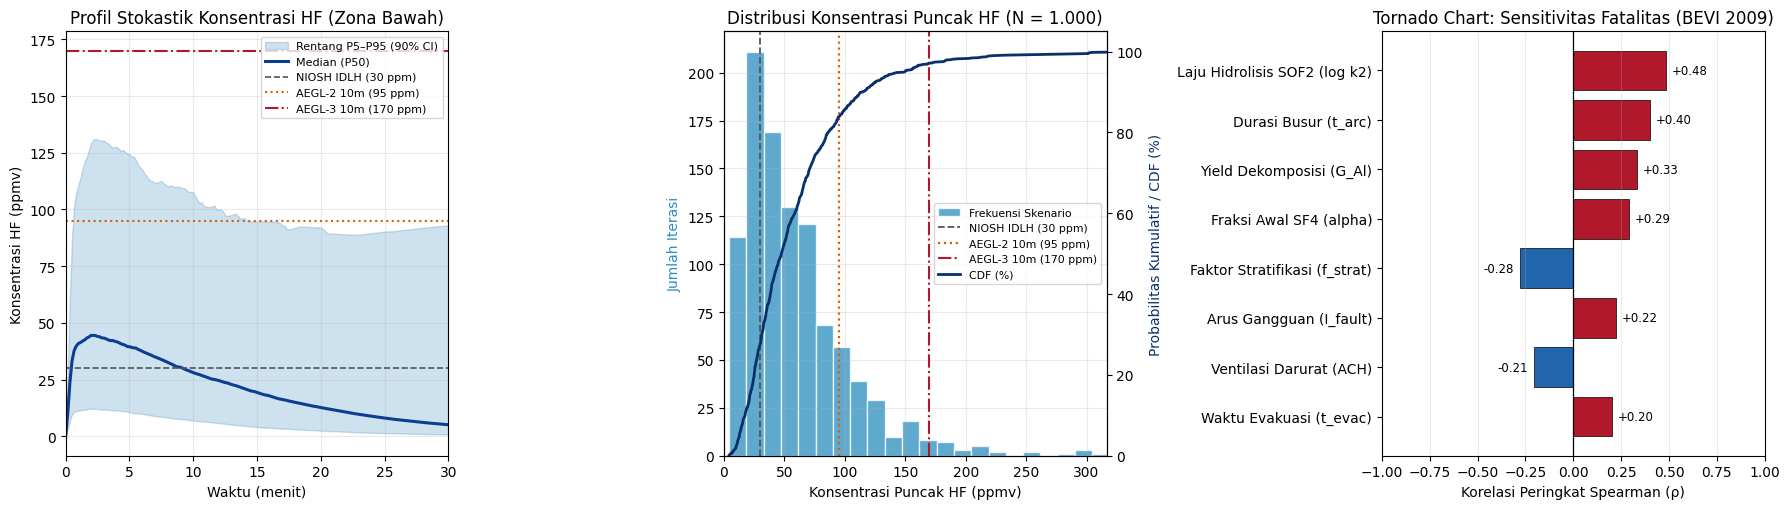

In [9]:
# %% [CELL 9] Visualisasi Stokastik: Pita Persentil, Distribusi Peak HF, & Tornado Chart (FINAL)
plt.rcParams.update({"axes.facecolor": "white", "figure.facecolor": "white"})
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# --- Panel 1: Pita Persentil Konsentrasi HF (P5 - P50 - P95) ---
p5_hf = np.percentile(hf_curves, 5, axis=0)
p50_hf = np.percentile(hf_curves, 50, axis=0)
p95_hf = np.percentile(hf_curves, 95, axis=0)

axes[0].fill_between(t_grid_min, p5_hf, p95_hf, color="#1f77b4", alpha=0.22, label="Rentang P5–P95 (90% CI)")
axes[0].plot(t_grid_min, p50_hf, color="#0b3d91", linewidth=2.2, label="Median (P50)")
axes[0].axhline(AEGL_HF["IDLH (NIOSH)"], color="#555555", linestyle="--", linewidth=1.2, label="NIOSH IDLH (30 ppm)")
axes[0].axhline(AEGL_HF["AEGL-2 (10 min)"], color="#d95f02", linestyle=":", linewidth=1.5, label="AEGL-2 10m (95 ppm)")
axes[0].axhline(AEGL_HF["AEGL-3 (10 min)"], color="#b2182b", linestyle="-.", linewidth=1.5, label="AEGL-3 10m (170 ppm)")
axes[0].set_xlim(0, 30)
axes[0].set_title("Profil Stokastik Konsentrasi HF (Zona Bawah)")
axes[0].set_xlabel("Waktu (menit)")
axes[0].set_ylabel("Konsentrasi HF (ppmv)")
axes[0].legend(fontsize=8, frameon=True)
axes[0].grid(True, alpha=0.25)

# --- Panel 2: Histogram & CDF Konsentrasi Puncak HF (Peak_HF) ---
peak_hf_vals = df_mc["Peak_HF (ppm)"].values
axes[1].hist(peak_hf_vals, bins=35, color="#2b8cbe", edgecolor="white", alpha=0.75, label="Frekuensi Skenario")
axes[1].axvline(AEGL_HF["IDLH (NIOSH)"], color="#555555", linestyle="--", linewidth=1.3, label="NIOSH IDLH (30 ppm)")
axes[1].axvline(AEGL_HF["AEGL-2 (10 min)"], color="#d95f02", linestyle=":", linewidth=1.6, label="AEGL-2 10m (95 ppm)")
axes[1].axvline(AEGL_HF["AEGL-3 (10 min)"], color="#b2182b", linestyle="-.", linewidth=1.5, label="AEGL-3 10m (170 ppm)")
axes[1].set_xlabel("Konsentrasi Puncak HF (ppmv)")
axes[1].set_ylabel("Jumlah Iterasi", color="#2b8cbe")
axes[1].set_title("Distribusi Konsentrasi Puncak HF (N = 1.000)")
axes[1].set_xlim(0, np.percentile(peak_hf_vals, 99.5) * 1.05)
axes[1].grid(True, alpha=0.25)

ax2_twin = axes[1].twinx()
sorted_hf = np.sort(peak_hf_vals)
cdf_y = np.arange(1, len(sorted_hf) + 1) / len(sorted_hf) * 100
ax2_twin.plot(sorted_hf, cdf_y, color="#08306b", linewidth=2.0, label="CDF (%)")
ax2_twin.set_ylabel("Probabilitas Kumulatif / CDF (%)", color="#08306b")
ax2_twin.set_ylim(0, 105)

# Gabungkan legenda sumbu kiri & kanan agar tampil rapi dalam satu kotak
lines_1, labels_1 = axes[1].get_legend_handles_labels()
lines_2, labels_2 = ax2_twin.get_legend_handles_labels()
axes[1].legend(lines_1 + lines_2, labels_1 + labels_2, loc="center right", fontsize=7.8, frameon=True)

# --- Panel 3: Tornado Chart (Analisis Sensitivitas Korelasi Spearman terhadap TNO BEVI 2009) ---
input_cols = [
    "I_fault (kA)", "t_arc (ms)", "G_yield (nmol/J)",
    "alpha_SF4", "log10_k2", "f_strat", "ACH_emerg", "t_evac (min)"
]
label_map = {
    "I_fault (kA)": "Arus Gangguan (I_fault)",
    "t_arc (ms)": "Durasi Busur (t_arc)",
    "G_yield (nmol/J)": "Yield Dekomposisi (G_Al)",
    "alpha_SF4": "Fraksi Awal SF4 (alpha)",
    "log10_k2": "Laju Hidrolisis SOF2 (log k2)",
    "f_strat": "Faktor Stratifikasi (f_strat)",
    "ACH_emerg": "Ventilasi Darurat (ACH)",
    "t_evac (min)": "Waktu Evakuasi (t_evac)"
}

corr_data = []
for col in input_cols:
    rho, _ = spearmanr(df_mc[col], df_mc["Pf_evac_BEVI (%)"])
    corr_data.append((label_map[col], rho))

df_tornado = pd.DataFrame(corr_data, columns=["Parameter", "Spearman_Rho"])
df_tornado["Abs_Rho"] = df_tornado["Spearman_Rho"].abs()
df_tornado = df_tornado.sort_values("Abs_Rho", ascending=True)

colors = ["#b2182b" if r > 0 else "#2166ac" for r in df_tornado["Spearman_Rho"]]
axes[2].barh(df_tornado["Parameter"], df_tornado["Spearman_Rho"], color=colors, edgecolor="black", linewidth=0.5)
axes[2].axvline(0, color="black", linewidth=0.9)
axes[2].set_xlim(-1.0, 1.0)
axes[2].set_title("Tornado Chart: Sensitivitas Fatalitas (BEVI 2009)")
axes[2].set_xlabel("Korelasi Peringkat Spearman (ρ)")
axes[2].grid(True, axis="x", alpha=0.25)

for idx, (val, name) in enumerate(zip(df_tornado["Spearman_Rho"], df_tornado["Parameter"])):
    offset = 0.03 if val >= 0 else -0.03
    ha = "left" if val >= 0 else "right"
    axes[2].text(val + offset, idx, f"{val:+.2f}", va="center", ha=ha, fontsize=8.5)

plt.tight_layout()
plt.show()